# Step 1: Data Exploration and Preprocessing

* Import the required libraries.
* Load the used car dataset.
* Display the first five rows, check for missing values, and find the dataset dimensions.
* Remove unnecessary columns.
* Analyze the basic statistics of the features.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance


df=pd.read_csv("cardekho_imputated.csv")
df.head()

,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [25]:
df.shape

(14996, 12)

In [2]:
df.isnull().sum()

Unnamed: 0           0
car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64

In [3]:
df=df.drop(columns=['Unnamed: 0','car_name'])

In [4]:
df.describe(include='all')

,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
count,15411,15411,15411.000000,1.541100e+04,15411,15411,15411,15411.000000,15411.000000,15411.000000,15411.000000,1.541100e+04
unique,32,120,NaN,NaN,3,5,2,NaN,NaN,NaN,NaN,NaN
top,Maruti,i20,NaN,NaN,Dealer,Petrol,Manual,NaN,NaN,NaN,NaN,NaN
freq,4992,906,NaN,NaN,9539,7643,12225,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,6.036338,5.561648e+04,NaN,NaN,NaN,19.701151,1486.057751,100.588254,5.325482,7.749711e+05
std,NaN,NaN,3.013291,5.161855e+04,NaN,NaN,NaN,4.171265,521.106696,42.972979,0.807628,8.941284e+05
min,NaN,NaN,0.000000,1.000000e+02,NaN,NaN,NaN,4.000000,793.000000,38.400000,0.000000,4.000000e+04
25%,NaN,NaN,4.000000,3.000000e+04,NaN,NaN,NaN,17.000000,1197.000000,74.000000,5.000000,3.850000e+05
50%,NaN,NaN,6.000000,5.000000e+04,NaN,NaN,NaN,19.670000,1248.000000,88.500000,5.000000,5.560000e+05
75%,NaN,NaN,8.000000,7.000000e+04,NaN,NaN,NaN,22.700000,1582.000000,117.300000,5.000000,8.250000e+05


# Step 2: EDA

* Analyze the distribution of numerical features using histograms.
* Identify different categories in nominal features.
* Find useful insights such as:
    * Cars with the highest mileage.
    * Fuel type with the best mileage.
    * Top 10 best-selling car models.
* Plot a heatmap to analyze correlations between numerical features.
* Use scatter plots and box plots to identify relationships and outliers.

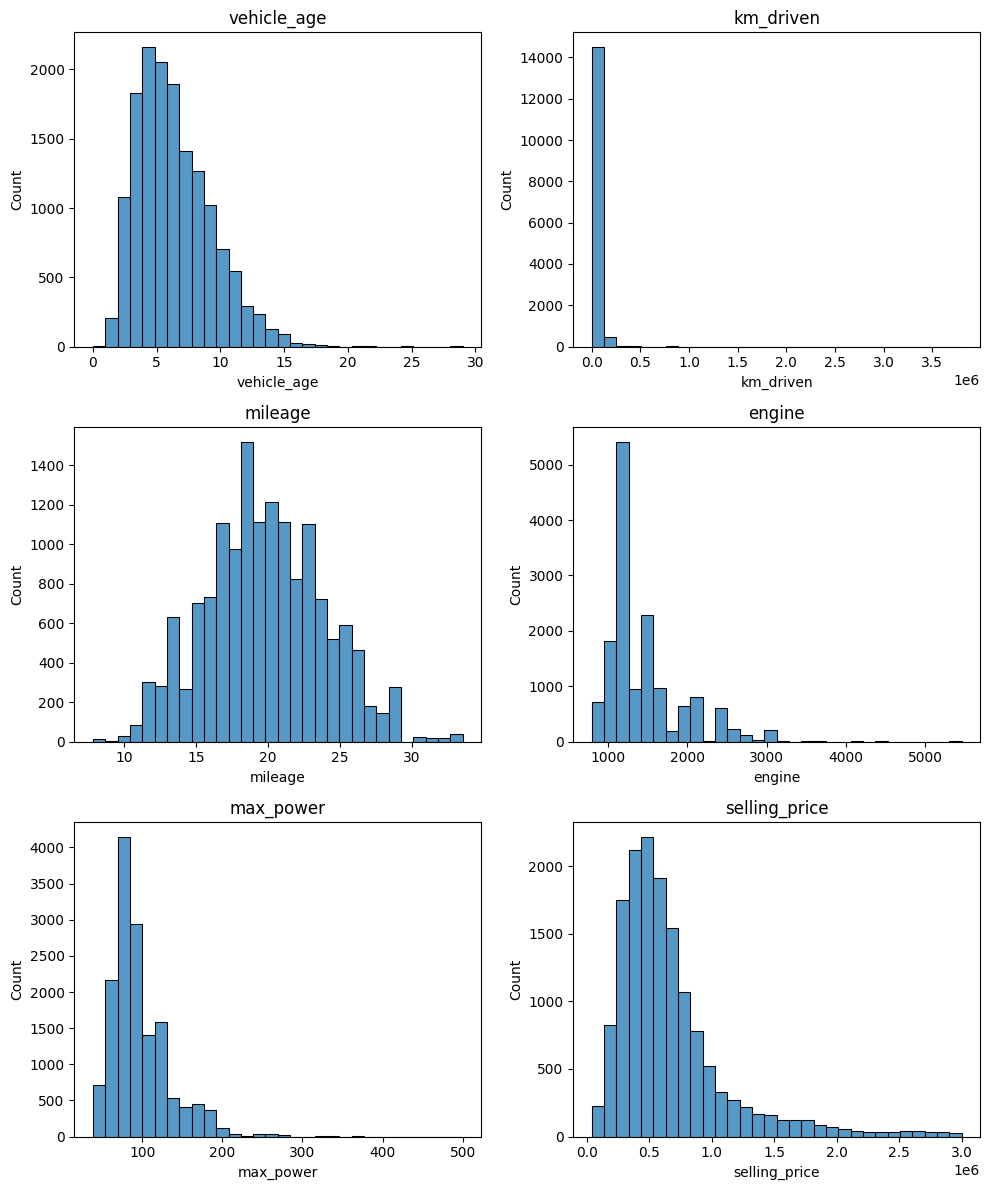

In [26]:
cols = ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'selling_price']

fig, axes = plt.subplots(3, 2, figsize=(10, 12))

for i, col in enumerate(cols):
    sns.histplot(df[col], bins=30, ax=axes[i//2, i%2])
    axes[i//2, i%2].set_title(col)

plt.tight_layout()
plt.show()
    

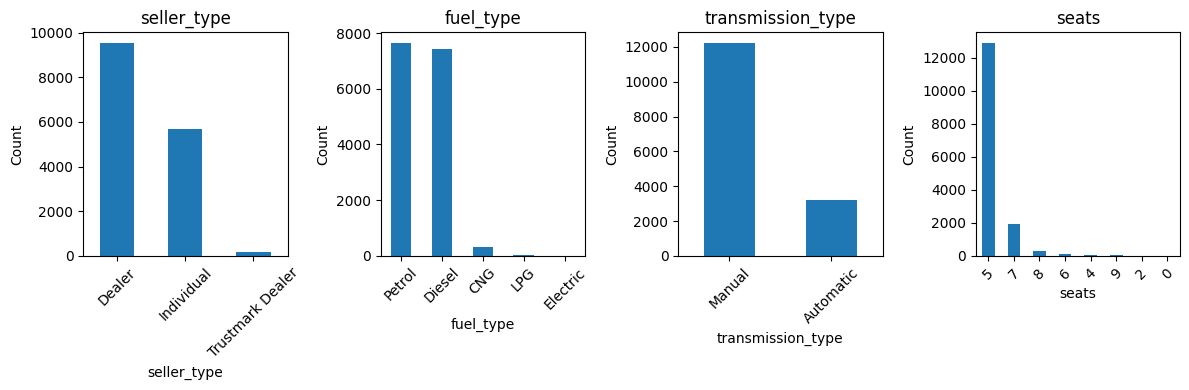

In [ ]:
nominal_columns=['seller_type','fuel_type','transmission_type','seats']

plt.figure(figsize=(12, 4))

for j, i in enumerate(nominal_columns, 1):

    plt.subplot(1, 4, j)
    df[i].value_counts().plot(kind='bar')
    plt.title(i)
    plt.xlabel(i)
    plt.ylabel('Count')
    plt.xticks(rotation=45)
    
plt.tight_layout()
plt.show()


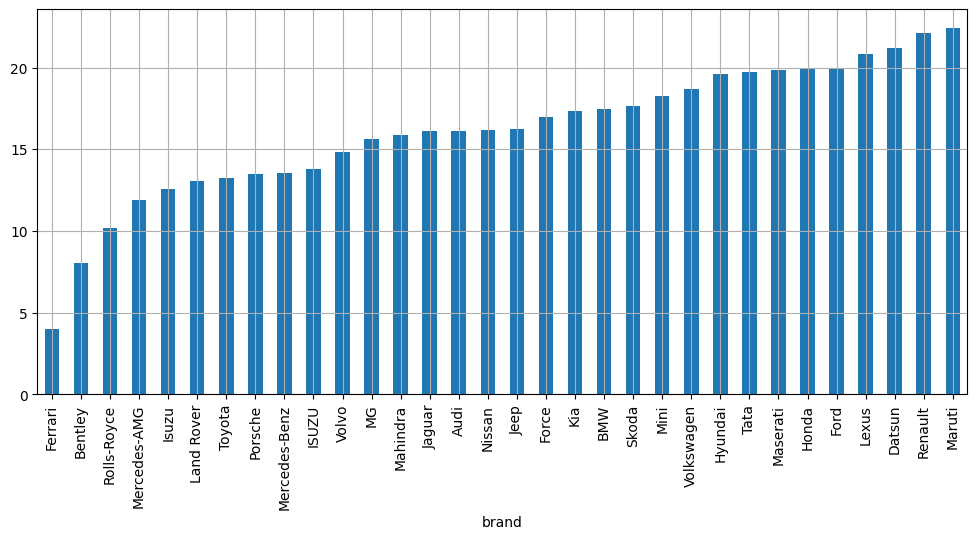

In [ ]:
plt.figure(figsize=(12,5))
df.groupby('brand')['mileage'].mean().sort_values().plot(kind='bar')
plt.grid()

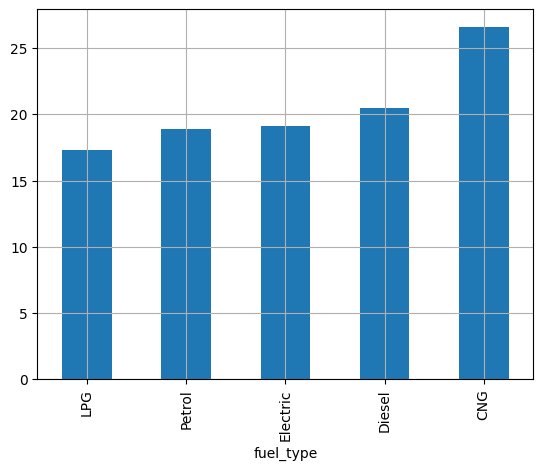

In [ ]:
df.groupby('fuel_type')['mileage'].median().sort_values().plot(kind='bar')
plt.grid()

Text(0.5, 1.0, 'Top 10 Best-Selling Car Models')

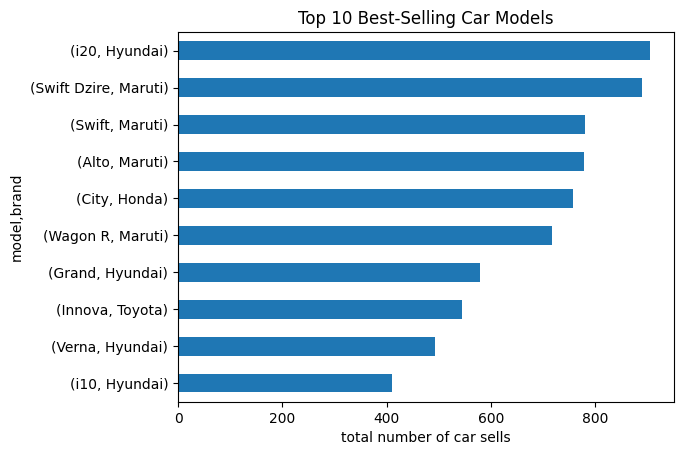

In [ ]:
df[['model','brand']].value_counts().nlargest(10).sort_values().plot(kind='barh')
plt.xlabel("total number of car sells")
plt.title("Top 10 Best-Selling Car Models")

<Axes: >

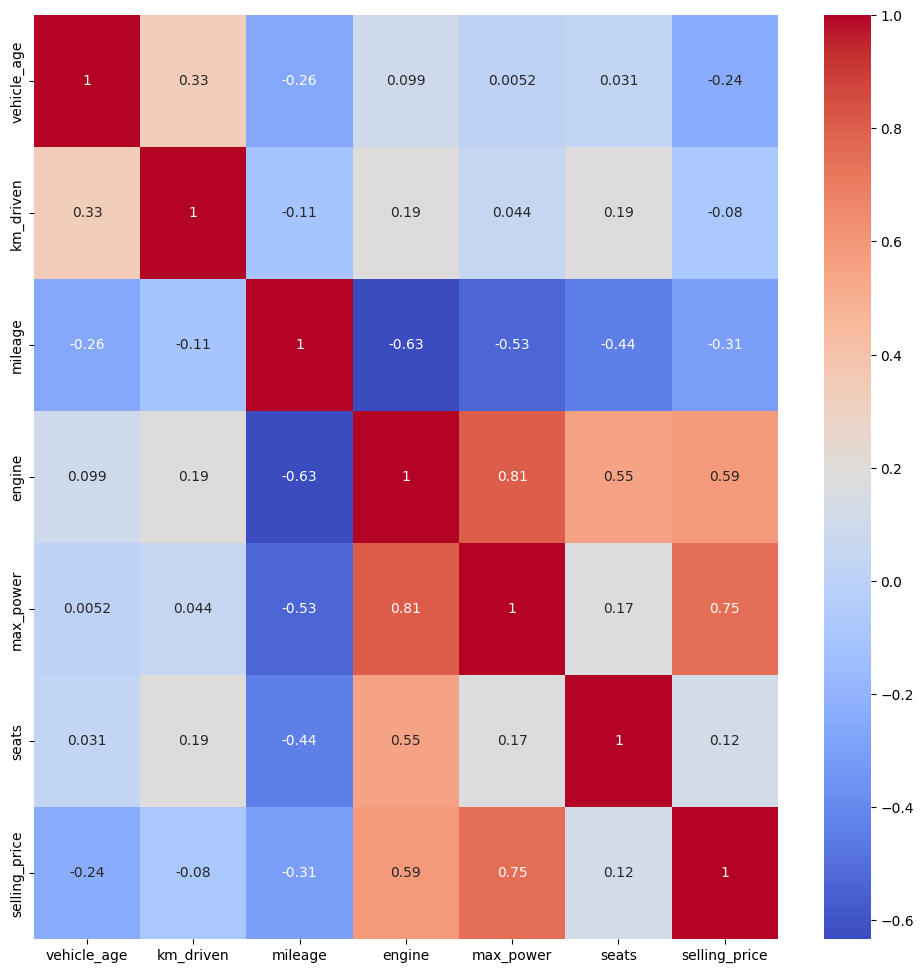

In [10]:
plt.figure(figsize=(12,12))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='coolwarm')

<Axes: xlabel='km_driven', ylabel='selling_price'>

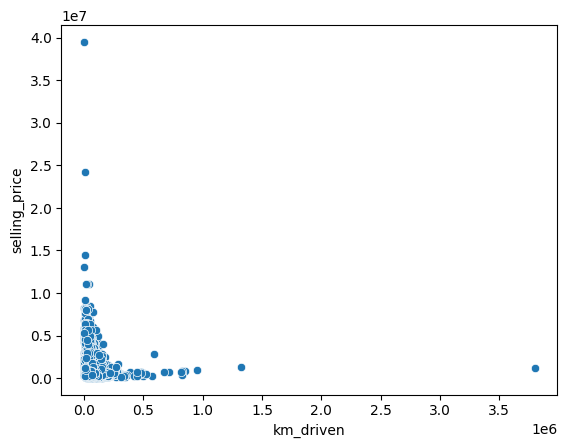

In [11]:
sns.scatterplot(x=df['km_driven'],y=df['selling_price'])

<Axes: xlabel='selling_price'>

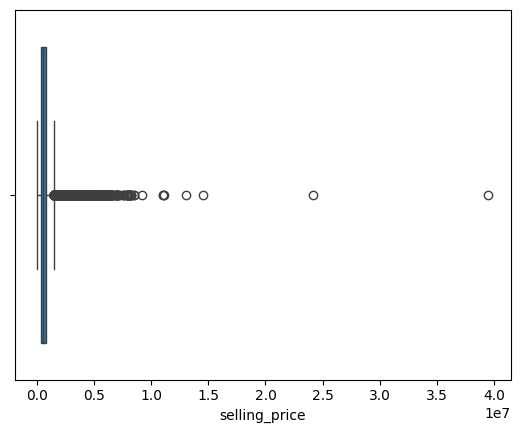

In [12]:
sns.boxplot(x='selling_price',data=df)

In [13]:
round(df['selling_price'].describe(percentiles=[0.90,0.95,0.97,0.99]))

count       15411.0
mean       774971.0
std        894128.0
min         40000.0
90%       1375000.0
95%       2050000.0
97%       2850000.0
99%       4545000.0
max      39500000.0
Name: selling_price, dtype: float64

In [ ]:
df=df[df['selling_price']<3000000]

# Step 3: Column Transformation and Model Training

* Split the dataset into training and testing sets.
* Use ColumnTransformer to apply One-Hot Encoding to categorical features and StandardScaler to numerical features.
* Combine the column transformer and ANN model using a pipeline.
* Build and train the Artificial Neural Network (ANN) model.
* Evaluate the model using R² Score, MAE, and RMSE


In [28]:


X=df.drop(columns=['selling_price'])
y=df['selling_price']

x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

column_transformer = ColumnTransformer([
    ("One_hot",
     OneHotEncoder(handle_unknown='ignore', sparse_output=False),
     ['seller_type', 'fuel_type', 'transmission_type', 'brand', 'model']),

    ("StandardScaler",
     StandardScaler(),
     ['vehicle_age', 'km_driven', 'mileage',
      'engine', 'max_power', 'seats'])
])

model = Pipeline([
    ("Transformer", column_transformer),


    ("model", MLPRegressor(
        hidden_layer_sizes=(128, 64, 32, 16),
        activation="relu",
        solver="adam",
        max_iter=1000,
        random_state=42,
        learning_rate_init=0.005
    ))
])

model.fit(x_train,y_train)


y_test_pred = model.predict(x_test)
test_r2 = r2_score(y_test, y_test_pred)
test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = mean_squared_error(y_test, y_test_pred) ** 0.5

print("Testing R2   :", test_r2)
print("Testing MAE  :", test_mae)
print("Testing RMSE :", test_rmse)

Testing R2   : 0.9302304437791347
Testing MAE  : 77840.73143957785
Testing RMSE : 124504.20220620467


# Step 4: Hyperparameter Tuning and Overfitting Check

* Find the best ANN hyperparameters using RandomizedSearchCV.
* Perform cross-validation to check for overfitting and model stability.
* Train the final ANN model using the best parameters.
* Plot Actual vs. Predicted Prices to evaluate model performance.
* Plot the feature importance graph to identify the most influential features.

In [16]:

y_train_pred = model.predict(x_train)
y_test_pred = model.predict(x_test)


train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)


train_mae = mean_absolute_error(y_train, y_train_pred)
test_mae = mean_absolute_error(y_test, y_test_pred)


train_rmse = mean_squared_error(y_train, y_train_pred) ** 0.5
test_rmse = mean_squared_error(y_test, y_test_pred) ** 0.5

print("Training R2  :", train_r2)
print("Testing R2   :", test_r2)

print("\nTraining MAE :", train_mae)
print("Testing MAE  :", test_mae)

print("\nTraining RMSE:", train_rmse)
print("Testing RMSE :", test_rmse)

print("\nR2 Gap       :", train_r2 - test_r2)

Training R2  : 0.9483174902817728
Testing R2   : 0.9326431642212755

Training MAE : 68656.6242662036
Testing MAE  : 76872.55228820548

Training RMSE: 103244.41916643601
Testing RMSE : 122332.50476864266

R2 Gap       : 0.015674326060497346


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

param_grid = {
    "model__hidden_layer_sizes": [
        (64, 32),
        (128, 64),
        (128, 64, 32),
        (128, 64, 32, 16),
        (256, 128, 64),
        (256, 128, 64, 32)
    ],

    "model__activation": ["relu"],
    "model__solver": ["adam"],
    "model__learning_rate_init": [0.0005, 0.001, 0.002, 0.005],
    "model__alpha": [0.00001, 0.0001, 0.001, 0.01],
    "model__batch_size": [32, 64, 128],
    "model__max_iter": [500, 1000]
}

random_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=30,
    cv=5,
    scoring="r2",
    random_state=42,
    n_jobs=-1,
    verbose=2
)

random_search.fit(x_train, y_train)

print("\nBest Parameters:")
print(random_search.best_params_)

print("\nBest CV R²:")
print(random_search.best_score_)

best_model = random_search.best_estimator_

y_pred = best_model.predict(x_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("\nTest Results:")
print("R²  :", r2)
print("MAE :", mae)
print("RMSE:", rmse)

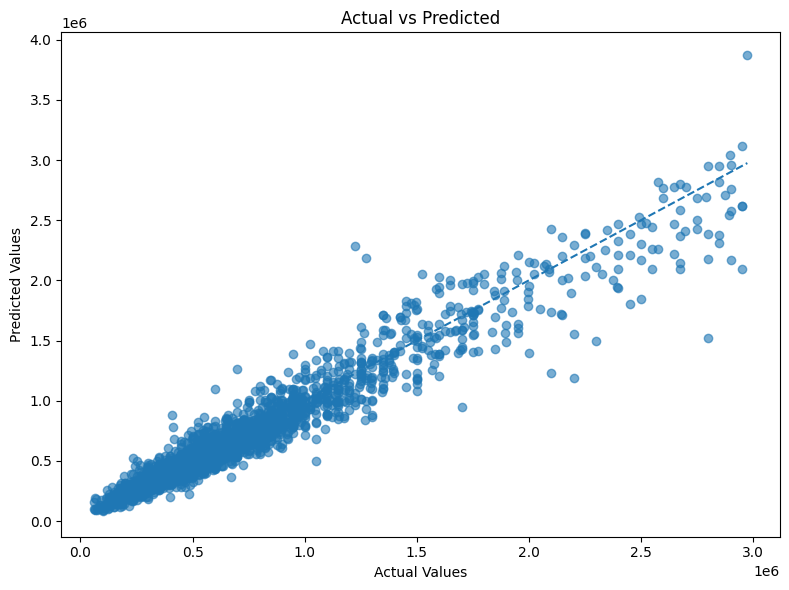

In [ ]:
import matplotlib.pyplot as plt

y_pred = model.predict(x_test)

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)


plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted")

plt.tight_layout()
plt.show()

In [29]:
from sklearn.model_selection import KFold, cross_val_score
import numpy as np


kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=kf,
    scoring='r2',
    n_jobs=-1
)

print("R2 scores for each fold:")
print(cv_scores)

print("Mean CV R2:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

R2 scores for each fold:
[0.92654923 0.9412574  0.93747889 0.92180856 0.92889077]
Mean CV R2: 0.9311969719006431
Standard Deviation: 0.007151742482084581


              Feature  Importance
1               model    0.604424
2         vehicle_age    0.553289
0               brand    0.295595
9           max_power    0.090734
6   transmission_type    0.023330
7             mileage    0.012579
5           fuel_type    0.011450
3           km_driven    0.007553
8              engine    0.002509
4         seller_type    0.002201
10              seats    0.001733


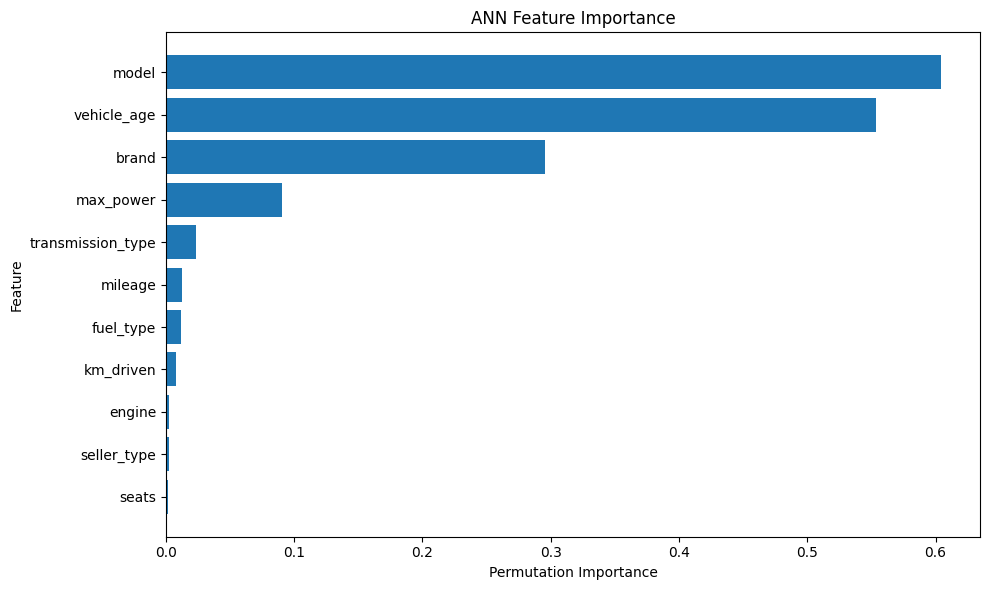

In [ ]:



result = permutation_importance(
    model,
    x_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="r2",
    n_jobs=-1
)


feature_names = x_test.columns


importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": result.importances_mean
})


importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)


plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1]
)

plt.xlabel("Permutation Importance")
plt.ylabel("Feature")
plt.title("ANN Feature Importance")
plt.tight_layout()
plt.show()

In [19]:
import joblib

joblib.dump(model, "ann_model.pkl")

['ann_model.pkl']

# Final Report

## Used Car Price Prediction Using Artificial Neural Network (ANN)

## 1. Introduction

This project aims to predict the selling price of used cars using an Artificial Neural Network (ANN). The model uses vehicle specifications and categorical information to estimate the selling price.

## 2. Dataset

The CarDekho used-car dataset contains information such as:

- Brand
- Model
- Vehicle Age
- Kilometres Driven
- Seller Type
- Fuel Type
- Transmission Type
- Mileage
- Engine
- Max Power
- Seats
- Selling Price

## Step 1: Data Exploration and Preprocessing

- Import the required libraries.
- Load the used car dataset.
- Display the first five rows, check missing values, and find the dataset dimensions.
- Remove unnecessary columns.
- Analyze the basic statistics of the features.
- Remove extreme selling-price values above ₹30 lakh to reduce the influence of high-price outliers.

## Step 2: Exploratory Data Analysis (EDA)

- Analyze the distribution of numerical features using histograms.
- Identify different categories in nominal features.
- Find useful insights such as:
  - Cars with the highest mileage.
  - Fuel type with the best mileage.
  - Top 10 best-selling car models.
- Plot a correlation heatmap to analyze relationships between numerical features.
- Use scatter plots and box plots to identify relationships and outliers.

## Step 3: Column Transformation and Model Training

- Split the dataset into training and testing sets.
- Apply One-Hot Encoding to categorical features:
  - Seller Type
  - Fuel Type
  - Transmission Type
  - Brand
  - Model
- Apply StandardScaler to numerical features:
  - Vehicle Age
  - Km Driven
  - Mileage
  - Engine
  - Max Power
  - Seats
- Combine the preprocessing steps and ANN model using a Pipeline.
- Build and train the Artificial Neural Network.
- Evaluate the model using R² Score, MAE, and RMSE.

## Step 4: Hyperparameter Tuning and Overfitting Check

- Find the best ANN hyperparameters using RandomizedSearchCV.
- Use 5-fold cross-validation to evaluate model stability and check for overfitting.
- Train the final ANN model using the best parameters.
- Plot Actual vs Predicted Selling Price.
- Plot feature importance to identify the most influential features.

## 3. Model Results

| Metric | Result |
|---|---:|
| R² Score | 0.93 |
| MAE | ₹77,000 approximately |
| RMSE | ₹1.22 lakh approximately |
| Mean 5-Fold CV R² | 0.9312 |

The ANN model achieved an R² score of approximately **0.93**, indicating strong predictive performance.

## 4. Overfitting Analysis

The training and testing R² scores were approximately **0.9483** and **0.9326**, respectively.

The small difference between training and testing performance indicates that the model does not show significant overfitting.

## 5. Feature Importance

The most important features identified by permutation importance were:

1. Model
2. Vehicle Age
3. Brand
4. Max Power
5. Transmission Type

Among these, **Model, Vehicle Age, and Brand** had the greatest influence on used-car selling prices.

## 6. Conclusion

The ANN model successfully predicted used-car selling prices with an R² score of approximately **0.93**. Data preprocessing, feature transformation, hyperparameter tuning, and cross-validation helped improve the reliability and performance of the model.

The results show that **Model, Vehicle Age, and Brand** are the most influential factors in predicting used-car prices.